# TP2 – Clase 3: detector de máximo enfoque en el dominio de la frecuencia

**Objetivo.** Implementar un detector de máximo enfoque sobre un video (`focus_video.mov`) con una métrica de análisis espectral, como las que usan las cámaras digitales.

**Métrica** (De & Masilamani, *Image Sharpness Measure for Blurred Images in Frequency Domain*, 2013):

1. `F = fftshift(fft2(imagen_gris))`
2. `AF = |F|`
3. umbral = `max(AF) / 1000`
4. `TH` = cantidad de coeficientes de `AF` por encima del umbral
5. **ISM = TH / (alto · ancho)**

Una imagen nítida conserva muchas componentes de alta frecuencia fuertes, así que más coeficientes superan el umbral. Una desenfocada concentra la energía cerca del centro del espectro y el ISM baja.

**Experimentos.** (1) medición sobre todo el frame; (2) medición sobre una ROI central de 5% y de 10% del área. Para cada uno: curva del ISM frame a frame y detección automática del máximo enfoque. **Extra:** unsharp masking para expandir la zona de enfoque.

In [1]:
import os
import matplotlib.pyplot as plt

# ---- Configuración ----
# Prioridad: variable de entorno, carpeta actual, Colab y entorno de evaluación.
from pathlib import Path
candidatos = [Path.cwd() / "focus_video.mov", Path("/content/focus_video.mov"), Path("/mnt/data/focus_video.mov")]
VIDEO_PATH = os.environ.get("TP2_VIDEO") or next((str(p) for p in candidatos if p.is_file()), None)
if VIDEO_PATH is None or not Path(VIDEO_PATH).is_file():
    raise FileNotFoundError("No se encontró focus_video.mov. Colocalo junto al notebook, subilo a /content en Colab o definí TP2_VIDEO.")
print("Video:", VIDEO_PATH)
ROI_FRACS = (0.05, 0.10)          # área de la ROI central, como fracción del frame
UNSHARP_SIGMA, UNSHARP_AMOUNT = 2.0, 1.5   # parámetros del unsharp masking (extra)

import cv2
import numpy as np
from scipy.signal import find_peaks, savgol_filter

Video: /content/focus_video.mov


## 1. Métrica ISM y ROI central

In [2]:
def ism(gray, rel_thr=1 / 1000):
    """Image Sharpness Measure de una imagen (o región) en escala de grises."""
    g = np.asarray(gray, dtype=np.float64)
    af = np.abs(np.fft.fftshift(np.fft.fft2(g)))
    umbral = af.max() * rel_thr
    return float(np.count_nonzero(af > umbral)) / g.size


def roi_bounds(h, w, area_frac):
    """Límites (y0, y1, x0, x1) de una ROI centrada con `area_frac` del área total.
    Mantiene la proporción del frame: lado_roi = lado_frame * sqrt(area_frac)."""
    s = np.sqrt(area_frac)
    rh, rw = max(2, int(round(h * s))), max(2, int(round(w * s)))
    y0, x0 = (h - rh) // 2, (w - rw) // 2
    return y0, y0 + rh, x0, x0 + rw


def ism_roi(gray, area_frac):
    y0, y1, x0, x1 = roi_bounds(*gray.shape[:2], area_frac)
    return ism(gray[y0:y1, x0:x1])

## 2. Procesamiento del video
Lectura frame a frame y curvas del ISM (frame completo y ROI central).

In [3]:
def unsharp(img, sigma=2.0, amount=1.5):
    """Unsharp masking: img + amount * (img - blur(img))."""
    blur = cv2.GaussianBlur(img, (0, 0), sigma)
    return cv2.addWeighted(img, 1 + amount, blur, -amount, 0)


def iter_frames(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise FileNotFoundError(f"No se pudo abrir el video: {path}")
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            yield frame
    finally:
        cap.release()


def video_info(path):
    cap = cv2.VideoCapture(str(path))
    info = dict(frames=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
                fps=cap.get(cv2.CAP_PROP_FPS),
                width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    cap.release()
    return info


def video_curves(path, roi_fracs=(0.05, 0.10), preprocess=None):
    """Calcula el ISM frame a frame: frame completo y una ROI central por cada
    fracción de `roi_fracs`. `preprocess` (opcional) se aplica a cada frame BGR
    antes de medir (por ejemplo, unsharp masking)."""
    curvas = {"full": []}
    for f in roi_fracs:
        curvas[f"roi_{int(round(f * 100))}"] = []
    for frame in iter_frames(path):
        if preprocess is not None:
            frame = preprocess(frame)
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        curvas["full"].append(ism(gray))
        for f in roi_fracs:
            curvas[f"roi_{int(round(f * 100))}"].append(ism_roi(gray, f))
    return {k: np.array(v) for k, v in curvas.items()}


def extract_frames(path, start, end, preprocess=None):
    """Frames [start, end] del video (índices inclusivos), con `preprocess` opcional."""
    out = []
    for i, fr in enumerate(iter_frames(path)):
        if i > end:
            break
        if i >= start:
            out.append(preprocess(fr) if preprocess else fr)
    return out


def save_video(frames, path, fps=25.0):
    h, w = frames[0].shape[:2]
    vw = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
    for fr in frames:
        vw.write(fr)
    vw.release()
    return path

## 3. Detección automática del máximo enfoque
La curva se suaviza (Savitzky-Golay) y se buscan los picos con una prominencia mínima, relativa al rango de la curva. Si la cima es plana, el punto de máximo enfoque se ubica en el centro de la meseta. `focus_zone` mide el ancho de la zona de enfoque (frames con ISM normalizado ≥ 0.9).

In [4]:
def smooth_curve(y, window=None):
    """Suaviza la curva con Savitzky-Golay para que el ruido no genere picos falsos."""
    n = len(y)
    if window is None:
        window = max(5, (n // 25) | 1)  # ventana impar, ~4% del largo
    window = min(window, n if n % 2 == 1 else n - 1)
    if window < 5:
        return np.asarray(y, dtype=float)
    return savgol_filter(y, window, 2)


def normalize(y):
    y = np.asarray(y, dtype=float)
    rango = y.max() - y.min()
    return (y - y.min()) / rango if rango > 0 else np.zeros_like(y)


def detect_focus_peaks(y, prominence=0.4, min_distance=None, refine_level=0.97):
    """Detecta máximos de enfoque y centra mesetas respecto de cada pico local.

    Parámetros
    ----------
    y : array-like
        Serie temporal de valores de nitidez, uno por fotograma.
    prominence : float, default 0.4
        Prominencia mínima del pico sobre la curva suavizada y normalizada.
    min_distance : int o None, default None
        Separación mínima entre picos; None usa max(3, len(y)//20).
    refine_level : float o None, default 0.97
        Fracción de la altura del pico sobre su valle local para delimitar
        una meseta. None desactiva el centrado.

    Retorna
    -------
    dict
        peaks: índices enteros ordenados por nitidez suavizada descendente;
        values: valores suavizados en esos índices;
        smooth: curva suavizada completa.

    Notas
    -----
    La ubicación de una meseta puede no ser el máximo puntual de la curva.
    """
    ys = smooth_curve(y)
    yn = normalize(ys)
    if min_distance is None:
        min_distance = max(3, len(y) // 20)
    idx, props = find_peaks(yn, prominence=prominence, distance=min_distance)
    if not len(idx):
        idx = np.array([int(np.argmax(ys))])
        props = {"left_bases": np.array([0]), "right_bases": np.array([len(y)-1])}
    refined = []
    for j, peak in enumerate(idx):
        p = int(peak)
        if refine_level is not None:
            left_base = int(props["left_bases"][j])
            right_base = int(props["right_bases"][j])
            baseline = max(yn[left_base], yn[right_base])
            threshold = baseline + refine_level * (yn[p] - baseline)
            a = b = p
            while a > left_base and yn[a-1] >= threshold:
                a -= 1
            while b < right_base and yn[b+1] >= threshold:
                b += 1
            # Centro de meseta; su posición se justifica por proximidad al máximo.
            p = (a+b)//2
        refined.append(p)
    idx = np.unique(refined)
    idx = idx[np.argsort(ys[idx])[::-1]]
    return {"peaks": idx, "values": ys[idx], "smooth": ys}


def focus_zone(y, peak, level=0.9):
    """Rango contiguo de frames alrededor de `peak` cuyo ISM (normalizado 0-1)
    supera `level`. Sirve para medir el ancho de la zona de enfoque."""
    yn = normalize(smooth_curve(y))
    a = b = peak
    while a > 0 and yn[a - 1] >= level:
        a -= 1
    while b < len(yn) - 1 and yn[b + 1] >= level:
        b += 1
    return a, b


def focus_report(curves, fps, key="roi_10", **kwargs):
    """Puntos de máximo enfoque detectados sobre la curva `key`: lista de dicts con
    frame, tiempo (s) e ISM suavizado, ordenada de mejor a peor."""
    r = detect_focus_peaks(curves[key], **kwargs)
    return [dict(frame=int(p), tiempo_s=float(p) / fps, ism=float(v))
            for p, v in zip(r["peaks"], r["values"])]

## 4. Visualización
La grilla verde es la "matriz de enfoque" superpuesta sobre la ROI central.

In [5]:
def draw_roi_grid(frame, area_frac=0.10, n=8, color=(0, 255, 0)):
    """Dibuja sobre el frame la ROI central con una grilla de n x n celdas
    ("matriz de enfoque")."""
    out = frame.copy()
    y0, y1, x0, x1 = roi_bounds(*frame.shape[:2], area_frac)
    ys = np.linspace(y0, y1, n + 1).astype(int)
    xs = np.linspace(x0, x1, n + 1).astype(int)
    for i in range(n):
        for j in range(n):
            cv2.rectangle(out, (xs[j] + 2, ys[i] + 2), (xs[j + 1] - 2, ys[i + 1] - 2), color, 1)
    return out

## Experimentos 1 y 2: frame completo y ROI central

In [6]:
info = video_info(VIDEO_PATH)
print(info)
FPS = info["fps"] or 25.0

curvas = video_curves(VIDEO_PATH, ROI_FRACS)
etiquetas = {"full": "Frame completo", "roi_5": "ROI central 5%", "roi_10": "ROI central 10%"}

{'frames': 171, 'fps': 29.97002997002997, 'width': 640, 'height': 360}


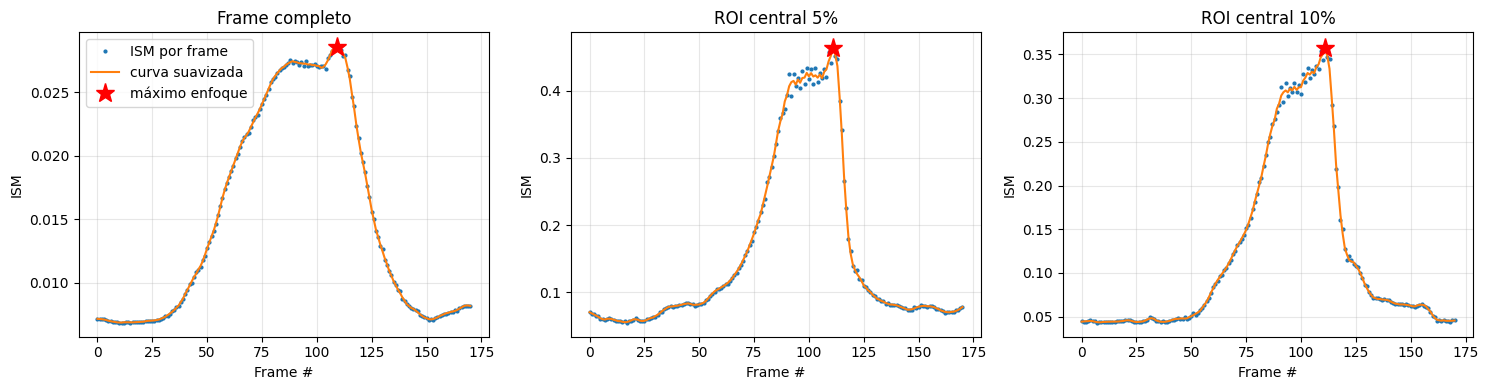

In [7]:
fig, ejes = plt.subplots(1, len(curvas), figsize=(5 * len(curvas), 4))
for ax, k in zip(ejes, curvas):
    r = detect_focus_peaks(curvas[k])
    ax.plot(curvas[k], ".", color="tab:blue", ms=4, label="ISM por frame")
    ax.plot(r["smooth"], "-", color="tab:orange", lw=1.5, label="curva suavizada")
    ax.plot(r["peaks"], r["values"], "r*", ms=14, label="máximo enfoque")
    ax.set_title(etiquetas[k]); ax.set_xlabel("Frame #"); ax.set_ylabel("ISM"); ax.grid(alpha=.3)
ejes[0].legend()
plt.tight_layout(); plt.savefig("curvas_ism.png", dpi=120); plt.show()

In [8]:
# Puntos de máximo enfoque detectados automáticamente, por cada medición
for k in curvas:
    pts = focus_report(curvas, FPS, key=k)
    print(f"{etiquetas[k]:16s}", [(p["frame"], round(p["tiempo_s"], 2), round(p["ism"], 4)) for p in pts], "(frame, t[s], ISM)")

Frame completo   [(109, 3.64, 0.0285)] (frame, t[s], ISM)
ROI central 5%   [(111, 3.7, 0.463)] (frame, t[s], ISM)
ROI central 10%  [(111, 3.7, 0.3572)] (frame, t[s], ISM)


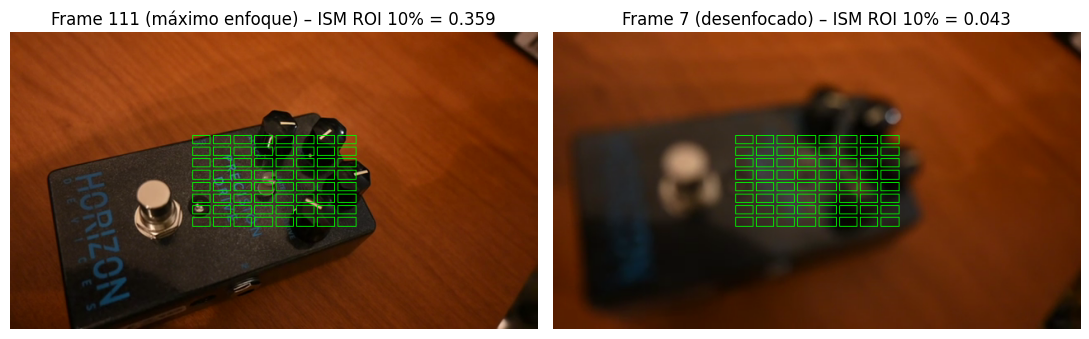

In [9]:
# Frame de máximo enfoque (ROI 10%) frente a un frame desenfocado, con la matriz de enfoque
best = focus_report(curvas, FPS, key="roi_10")[0]["frame"]
worst = int(np.argmin(curvas["roi_10"]))
cap = cv2.VideoCapture(VIDEO_PATH)
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, idx, tit in zip(ejes, (best, worst), ("máximo enfoque", "desenfocado")):
    cap.set(cv2.CAP_PROP_POS_FRAMES, idx); _, fr = cap.read()
    ax.imshow(cv2.cvtColor(draw_roi_grid(fr, 0.10), cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {idx} ({tit}) – ISM ROI 10% = {curvas['roi_10'][idx]:.3f}"); ax.axis("off")
cap.release(); plt.tight_layout(); plt.savefig("frames_enfoque.png", dpi=120); plt.show()

## Extra: unsharp masking para expandir la zona de enfoque
Se aplica unsharp masking a cada frame antes de medir y se compara el ancho de la zona de enfoque (ISM normalizado ≥ 0.9) con la medición original.

medición          ancho original  ancho con unsharp
Frame completo             33 fr              29 fr
ROI central 5%              7 fr              19 fr
ROI central 10%            11 fr              13 fr


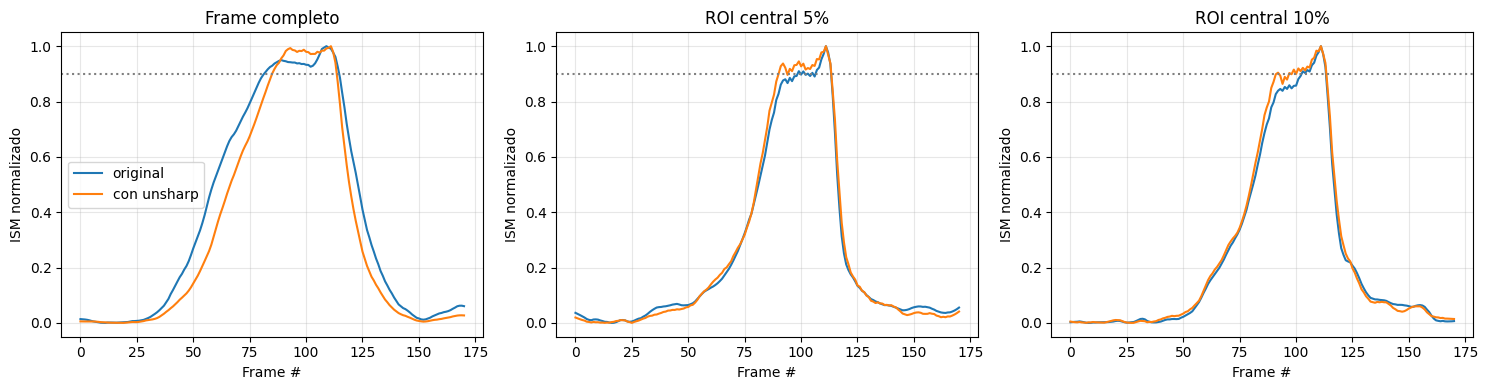

In [10]:
curvas_us = video_curves(VIDEO_PATH, ROI_FRACS, preprocess=lambda f: unsharp(f, UNSHARP_SIGMA, UNSHARP_AMOUNT))

fig, ejes = plt.subplots(1, len(curvas), figsize=(5 * len(curvas), 4))
print(f"{'medición':16s} {'ancho original':>15s} {'ancho con unsharp':>18s}")
for ax, k in zip(ejes, curvas):
    p0 = int(detect_focus_peaks(curvas[k])["peaks"][0]); p1 = int(detect_focus_peaks(curvas_us[k])["peaks"][0])
    z0, z1 = focus_zone(curvas[k], p0), focus_zone(curvas_us[k], p1)
    print(f"{etiquetas[k]:16s} {z0[1]-z0[0]+1:>12d} fr {z1[1]-z1[0]+1:>15d} fr")
    ax.plot(normalize(smooth_curve(curvas[k])), label="original")
    ax.plot(normalize(smooth_curve(curvas_us[k])), label="con unsharp")
    ax.axhline(0.9, color="gray", ls=":"); ax.set_title(etiquetas[k]); ax.set_xlabel("Frame #"); ax.set_ylabel("ISM normalizado"); ax.grid(alpha=.3)
ejes[0].legend(); plt.tight_layout(); plt.savefig("curvas_unsharp.png", dpi=120); plt.show()

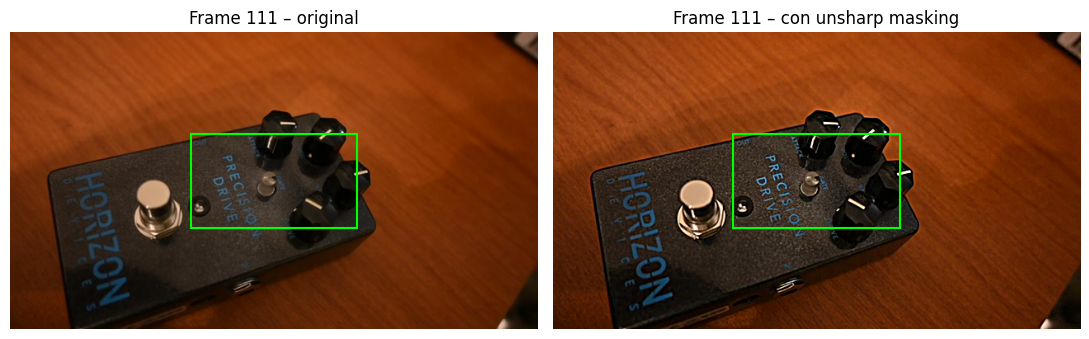

In [11]:
# Efecto visual del unsharp masking en el frame de máximo enfoque (recuadro verde = ROI 10%)
p_best = focus_report(curvas, FPS, key="roi_10")[0]["frame"]
cap = cv2.VideoCapture(VIDEO_PATH); cap.set(cv2.CAP_PROP_POS_FRAMES, p_best); _, fr = cap.read(); cap.release()
y0, y1, x0, x1 = roi_bounds(*fr.shape[:2], 0.10)
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, im, tit in zip(ejes, (fr, unsharp(fr, UNSHARP_SIGMA, UNSHARP_AMOUNT)), ("original", "con unsharp masking")):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="lime", lw=1.5))
    ax.set_title(f"Frame {p_best} – {tit}"); ax.axis("off")
plt.tight_layout(); plt.savefig("unsharp_frame.png", dpi=120); plt.show()

In [12]:
# "Devolver" la zona de enfoque: frames con unsharp masking dentro de la zona (ROI 10%)
k = "roi_10"
p = int(detect_focus_peaks(curvas_us[k])["peaks"][0])
a, b = focus_zone(curvas_us[k], p)
frames_zona = extract_frames(VIDEO_PATH, a, b, preprocess=lambda f: unsharp(f, UNSHARP_SIGMA, UNSHARP_AMOUNT))
save_video(frames_zona, "zona_enfoque_unsharp.mp4", FPS)
print(f"Zona de enfoque: frames {a}-{b} ({len(frames_zona)} frames) -> zona_enfoque_unsharp.mp4")

Zona de enfoque: frames 101-113 (13 frames) -> zona_enfoque_unsharp.mp4


## Resultados y conclusiones

**Video analizado:** `focus_video.mov` (171 frames, 29,97 fps, 640×360, ≈ 5,7 s).

| Medición | Frame de máximo enfoque | Tiempo | ISM en el pico (suavizado) | Ancho de la zona de enfoque* | Ancho con unsharp* |
|---|---|---|---|---|---|
| Frame completo | 109 | 3,64 s | 0,0285 | 33 frames | 29 frames |
| ROI central 5% | 111 | 3,70 s | 0,463 | 7 frames | 19 frames |
| ROI central 10% | 111 | 3,70 s | 0,357 | 11 frames | 13 frames |

\* Zona de enfoque = frames contiguos alrededor del pico con ISM normalizado (0–1) ≥ 0,9.

**1. Detección.** Las tres mediciones detectan el máximo enfoque entre los frames 109 y 111 (diferencia de 2 frames, ≈ 0,07 s), sin intervención manual. Al mirar los frames, el 111 es el más nítido: se leen el texto "PRECISION DRIVE" y los bordes de las perillas, mientras que en el frame 120 ya están desenfocados. Entonces, el ISM ubica el máximo enfoque en el mismo lugar donde lo ubica la inspección visual.

**2. Forma de la curva.** El ISM sube de forma gradual a medida que el foco se acerca al objeto (hasta el frame ~90), se mantiene en una meseta entre los frames ~90 y ~110 y cae de golpe después del 112, cuando el foco se pasa del punto óptimo. El máximo queda justo al final de la meseta, antes de esa caída. El rango del ISM entre el frame más desenfocado y el más nítido es de aproximadamente 4 veces en el frame completo (0,007 a 0,029) y de aproximadamente 8 veces en las ROI (0,055 a 0,466 con 5%, 0,043 a 0,359 con 10%).

**3. Frame completo vs. ROI.** Las curvas de las ROI son más angostas y de mayor contraste que la del frame completo. Una explicación razonable es que la ROI mide solo la zona del objeto (perillas, texto, bordes), mientras que el frame completo incluye la mesa y el fondo, que quedan desenfocados por la profundidad de campo y "diluyen" la métrica. Por eso la curva del frame completo es más ancha y suave, y su pico es menos selectivo. Con la ROI de 5% la zona de enfoque es la más angosta (7 frames), contra 11 con la de 10% y 33 con el frame completo.

**4. Tamaño de la ROI.** Una ROI chica es más selectiva y localiza mejor el pico, pero es más ruidosa (se nota en la dispersión entre frames de la meseta) y depende de que haya textura en el centro del encuadre. Una ROI grande promedia más información y es más estable, pero pierde sensibilidad. Con 10% se obtiene un compromiso razonable, y en este video ambas ROI dan el mismo frame (111).

**5. Unsharp masking (extra).** Aplicarlo antes de medir amplió la zona de enfoque en las dos ROI (de 7 a 19 frames con 5%, y de 11 a 13 con 10%), pero no en el frame completo, donde pasó de 33 a 29 frames. El efecto tiene sentido: el unsharp realza las altas frecuencias de los frames levemente desenfocados que rodean al óptimo, lo que sube su ISM respecto del máximo y los incorpora a la zona. Hay que tener en cuenta que el unsharp no recupera información que el desenfoque ya eliminó y que además amplifica el ruido, así que "expandir" la zona significa que más frames pasan a verse enfocados, no que lo estén realmente. Los parámetros usados fueron sigma = 2,0 y cantidad = 1,5.

**6. Limitaciones.**
- El valor absoluto del ISM depende del contenido de la escena, la resolución, el ruido y la compresión del video, así que solo es comparable entre frames de la misma escena. Lo importante es la forma de la curva y la posición del pico.
- El umbral es relativo al máximo del espectro, que normalmente es la componente continua (el brillo medio). Por eso cambios de iluminación o de exposición entre frames pueden alterar la métrica.
- Los valores de este video son más bajos que los de la curva de ejemplo de la consigna (0,5 a 0,9). Puede deberse a una variante del umbral o a un video distinto; el umbral relativo se puede cambiar con el parámetro `rel_thr` de `ism()`.
- La detección usa la prominencia de los picos en la curva suavizada, así que un video con varios barridos de foco devolvería varios máximos (la función ya devuelve todos, ordenados de mayor a menor ISM). Se probó con un solo video y un único barrido.

**Alcance metodológico:** la implementación emplea una variante espectral FFT con umbral relativo. No se afirma equivalencia exacta con el artículo citado hasta cotejar la formulación original. Los anchos tras unsharp masking son cambios de la métrica normalizada, no prueba de recuperación de detalle óptico.


## 5. Comprobaciones de consistencia y análisis de sensibilidad
Se revisan índices válidos y zonas calculadas por el detector (chequeos de integridad, **no validación independiente**). Luego se evalúa la estabilidad de los máximos al variar el umbral de Fourier.

In [13]:
# Comprobaciones internas de consistencia (no validación independiente)
for nombre, serie in curvas.items():
    det = detect_focus_peaks(serie)
    idx = int(det["peaks"][0])
    sm = det["smooth"]
    assert 0 <= idx < len(serie)
    a, b = focus_zone(serie, idx, level=0.90)
    assert a <= idx <= b
    max_global = int(np.argmax(sm))
    print(f"{nombre}: pico detectado={idx}; máximo suavizado={max_global}; zona90=[{a},{b}]")
print("Comprobaciones internas de índices y zonas: OK")

full: pico detectado=109; máximo suavizado=109; zona90=[82,114]
roi_5: pico detectado=111; máximo suavizado=111; zona90=[107,113]
roi_10: pico detectado=111; máximo suavizado=111; zona90=[103,113]
Comprobaciones internas de índices y zonas: OK


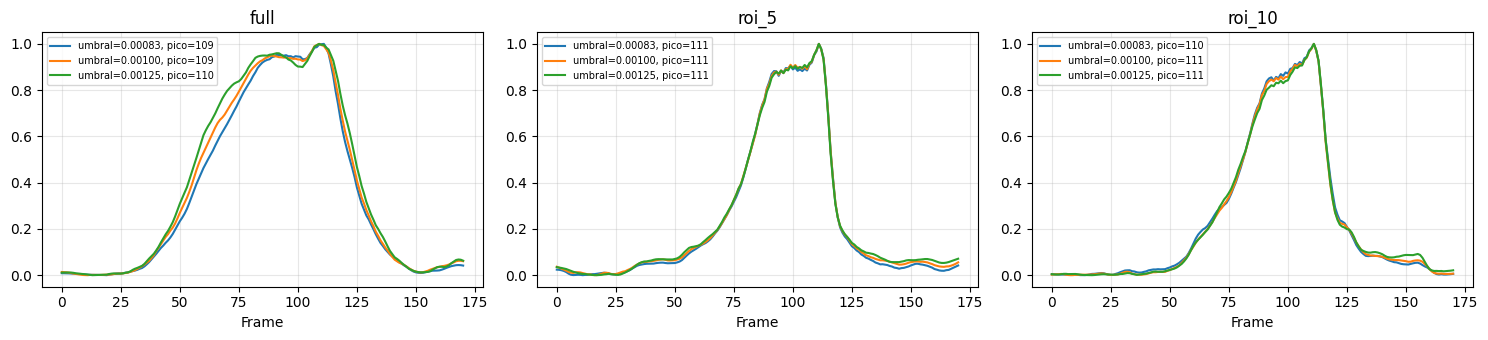


Sensibilidad del frame máximo al umbral FFT:
Frame completo: [109, 109, 110]; desplazamiento máximo = 1 frame(s)
ROI central 5%: [111, 111, 111]; desplazamiento máximo = 0 frame(s)
ROI central 10%: [110, 111, 111]; desplazamiento máximo = 1 frame(s)


In [14]:
# Sensibilidad a variaciones pequeñas del umbral de Fourier
umbrales = [1/1200, 1/1000, 1/800]
fig, axs = plt.subplots(1, 3, figsize=(15, 3.5))
resultados_sensibilidad = {k: {} for k in ("full", "roi_5", "roi_10")}
for umbral in umbrales:
    medidas = {"full": [], "roi_5": [], "roi_10": []}
    for frame in iter_frames(VIDEO_PATH):
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        medidas["full"].append(ism(gray, umbral))
        for frac, key in [(0.05, "roi_5"), (0.10, "roi_10")]:
            y0,y1,x0,x1 = roi_bounds(*gray.shape, frac)
            medidas[key].append(ism(gray[y0:y1,x0:x1], umbral))
    for ax, key in zip(axs, medidas):
        y = np.array(medidas[key])
        idx = int(detect_focus_peaks(y)["peaks"][0])
        resultados_sensibilidad[key][umbral] = idx
        ax.plot(normalize(smooth_curve(y)), label=f"umbral={umbral:.5f}, pico={idx}")
        ax.set_title(key); ax.set_xlabel("Frame"); ax.grid(alpha=.3)
for ax in axs: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
print("\nSensibilidad del frame máximo al umbral FFT:")
for key, valores in resultados_sensibilidad.items():
    print(f"{etiquetas[key]}: {list(valores.values())}; desplazamiento máximo = {max(valores.values())-min(valores.values())} frame(s)")


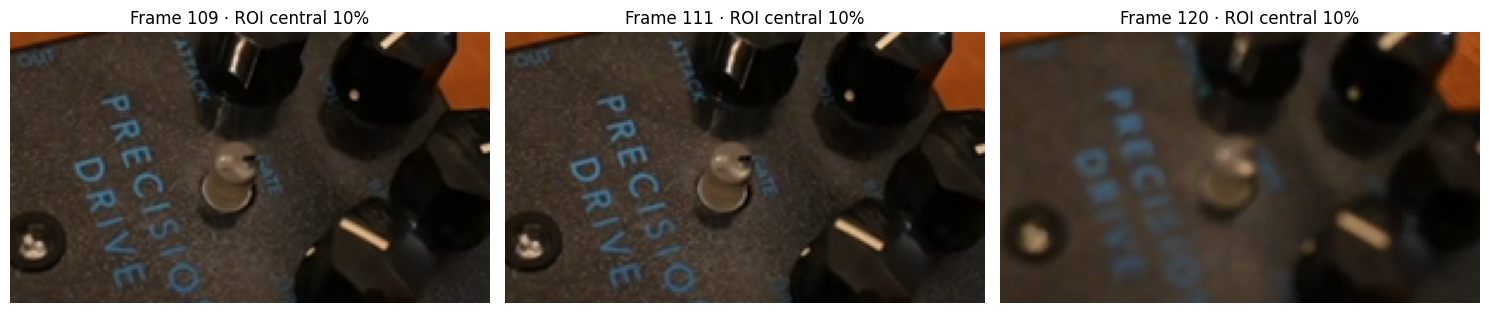

In [15]:
# Comparación visual con la MISMA región para los frames 109, 111 y 120
comparar = [109, 111, 120]
frames_comp = {}
for i, fr in enumerate(iter_frames(VIDEO_PATH)):
    if i in comparar: frames_comp[i] = fr.copy()
    if len(frames_comp) == len(comparar): break
fig, axs = plt.subplots(1, len(comparar), figsize=(15, 4))
for ax, i in zip(axs, comparar):
    fr = frames_comp[i]
    h,w = fr.shape[:2]
    y0,y1,x0,x1 = roi_bounds(h,w,.10)
    crop = fr[y0:y1,x0:x1]
    ax.imshow(cv2.cvtColor(crop,cv2.COLOR_BGR2RGB))
    ax.set_title(f"Frame {i} · ROI central 10%")
    ax.axis("off")
plt.tight_layout(); plt.show()

### Interpretación de la sensibilidad y comparación visual
Al cambiar el umbral relativo entre 1/1200, 1/1000 y 1/800, los máximos detectados se desplazan **a lo sumo un fotograma**: frame completo 109–110, ROI 10% 110–111 y ROI 5% siempre 111. Esto indica estabilidad local ante estos cambios de parametrización, no independencia absoluta del umbral. Los recortes de una misma ROI muestran los frames 109 y 111 visualmente nítidos, frente al 120 más desenfocado. El detector centra mesetas locales; ese centro no tiene por qué coincidir con el máximo puntual. Unsharp Masking realza bordes, pero también puede introducir halos o amplificar ruido.

## 6. Contraste con una segunda métrica: varianza del Laplaciano
La varianza del Laplaciano cuantifica la respuesta a cambios espaciales bruscos y permite contrastar los resultados del ISM. Se calcula sobre las **mismas regiones** y los **mismos fotogramas**. Se comparan máximos detectados con el mismo procedimiento y la correlación de Spearman entre las curvas originales, sin confundir concordancia con verdad óptica absoluta. Ambas métricas responden a altas frecuencias, por lo que no son físicamente independientes.

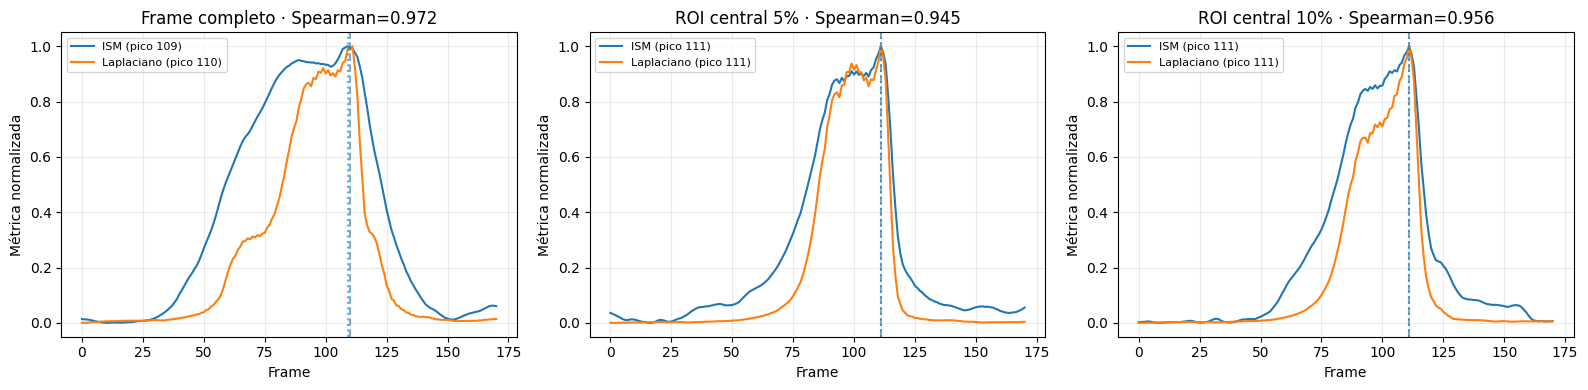

Región               ISM  Lap.  Δ frames   Spearman ρ
Frame completo       109   110         1       0.9717
ROI central 5%       111   111         0       0.9452
ROI central 10%      111   111         0       0.9559


In [16]:
from scipy.stats import spearmanr

def varianza_laplaciano(gray):
    """Varianza de la respuesta del Laplaciano de una imagen en gris."""
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())

curvas_lap = {k: [] for k in curvas}
for frame in iter_frames(VIDEO_PATH):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    curvas_lap["full"].append(varianza_laplaciano(gray))
    for frac, key in [(0.05, "roi_5"), (0.10, "roi_10")]:
        y0, y1, x0, x1 = roi_bounds(*gray.shape, frac)
        curvas_lap[key].append(varianza_laplaciano(gray[y0:y1, x0:x1]))
curvas_lap = {k: np.asarray(v, dtype=float) for k, v in curvas_lap.items()}

comparacion_metricas = []
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, key in zip(axs, curvas):
    i_ism = int(detect_focus_peaks(curvas[key])["peaks"][0])
    i_lap = int(detect_focus_peaks(curvas_lap[key])["peaks"][0])
    rho, pvalue = spearmanr(curvas[key], curvas_lap[key])
    comparacion_metricas.append((key, i_ism, i_lap, abs(i_ism-i_lap), rho, pvalue))
    ax.plot(normalize(smooth_curve(curvas[key])), label=f"ISM (pico {i_ism})")
    ax.plot(normalize(smooth_curve(curvas_lap[key])), label=f"Laplaciano (pico {i_lap})")
    ax.axvline(i_ism, ls=":", alpha=.6)
    ax.axvline(i_lap, ls="--", alpha=.6)
    ax.set(title=f"{etiquetas[key]} · Spearman={rho:.3f}", xlabel="Frame", ylabel="Métrica normalizada")
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("comparacion_ism_laplaciano.png", dpi=140)
plt.show()

print(f"{'Región':18s} {'ISM':>5s} {'Lap.':>5s} {'Δ frames':>9s} {'Spearman ρ':>12s}")
for key, a, b, delta, rho, pv in comparacion_metricas:
    print(f"{etiquetas[key]:18s} {a:5d} {b:5d} {delta:9d} {rho:12.4f}")


### Conclusión del contraste entre métricas
La coincidencia temporal de los máximos y la asociación de rangos entre las curvas se informan en la tabla anterior, calculada sobre el video cargado. Una diferencia de un frame equivale a aproximadamente 33 ms a 29,97 FPS. Esta concordancia, sumada a la sensibilidad acotada al umbral, refuerza la **consistencia empírica** del detector para este video; no garantiza que el fotograma sea el óptimo en términos de enfoque óptico. La definición exacta de ISM respecto del artículo citado sigue pendiente de contrastarse con el texto original.